# MF와 기준선·CB 비교, 점수 차이의 불확실성

C2·C3에서 고른 추천용 MF를 같은 독자, 같은 정답으로 다른 방법과 비교합니다. 모두 `train`으로 학습하고 `val`과 `cold_tune`으로만 잽니다.

| 비교 대상 | 내용 |
| --- | --- |
| 인기순 | `train`에서 평점 수가 많은 책 순 (`PopularityRecommender`) |
| Goodreads 평점순 | `books.csv`의 `average_rating`이 높은 책 순 (`GoodreadsRatingRecommender`) |
| bias | 전체 평균 + 독자 bias + 책 bias로 별점만 예측 (`BiasPredictor`). 추천 점수가 없어 RMSE만 비교 |
| CB | 팀원 B의 최종 content-based 모델 (`load_selected_content_based`) |

- 인기순, Goodreads 평점순, bias는 A6 기준선(`bookrec.models.baselines`)을 그대로 씁니다.
- 점수 차이는 독자를 다시 뽑는 bootstrap(2,000번, 시드 42)으로 95% 구간을 냅니다. 구간이 0을 포함하면 우열을 말하지 않습니다.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bookrec.data import load_books, load_split
from bookrec.evaluation import evaluate_rmse
# NOTE: 독자별 점수가 필요해서 평가 모듈 안쪽 함수 두 개를 그대로 가져다 쓴다(평균만 돌려주는 evaluate_warm/cold와 같은 계산).
from bookrec.evaluation.evaluate import COLD_HISTORY_SIZES, K, RELEVANT_RATING, _rank_metrics, _recommend
from bookrec.models.collaborative_filtering import fit_selected_mf
from bookrec.models.collaborative_filtering.tuning import RESULT_DIR, TUNING_USERS
from bookrec.models.baselines.bias import BiasPredictor
from bookrec.models.baselines.goodreads_rating import GoodreadsRatingRecommender
from bookrec.models.baselines.popularity import PopularityRecommender
from bookrec.models.content_based.tuning import load_selected_content_based
from bookrec.plot_style import MODEL_COLORS, save, setup

setup()
split = load_split()


models = {
    "popularity": PopularityRecommender().fit(split.train),
    "goodreads_rating": GoodreadsRatingRecommender(load_books()).fit(split.train),
    "cb": load_selected_content_based().fit(split.train),
    "mf_ranking": fit_selected_mf("ranking", split.train),
}
print(list(models))

['popularity', 'goodreads_rating', 'cb', 'mf_ranking']


## 1. 별점 예측 (검증 RMSE)

In [2]:
rating_model = fit_selected_mf("rating", split.train)
rmse_table = pd.DataFrame([
    {"model": "전체 평균", "val_rmse": float(np.sqrt(np.mean((split.val["rating"] - split.train["rating"].mean()) ** 2)))},
    {"model": "bias 기준선", "val_rmse": evaluate_rmse(BiasPredictor().fit(split.train), split, on="val")},
    {"model": f"MF 별점 예측용 ({type(rating_model).__name__})", "val_rmse": evaluate_rmse(rating_model, split, on="val")},
])
rmse_table.to_csv(RESULT_DIR / "C2c_val_rmse.csv", index=False)
rmse_table.round(4)

,model,val_rmse
0,전체 평균,0.9865
1,bias 기준선,0.8616
2,MF 별점 예측용 (ALSMatrixFactorization),0.8392


## 2. 독자별 추천 점수

`evaluate_warm(on="val", n_users=5000)`, `evaluate_cold(on="tune")`과 같은 독자·이력·정답으로 독자별 NDCG@10을 구합니다.

In [3]:
# 기존 독자: evaluate_warm과 같은 방식으로 val 독자 5,000명을 뽑는다(시드 42).
val_users = np.sort(split.val["user_id"].unique())
warm_users = np.random.default_rng(42).choice(val_users, size=TUNING_USERS, replace=False)
warm_history = split.train[split.train["user_id"].isin(warm_users)]
warm_answers = split.val[split.val["rating"] >= RELEVANT_RATING]

# 신규 독자: evaluate_cold와 같은 방식으로 앞 s개를 이력, 앞 10개를 읽은 책, 11번째부터 4점 이상을 정답으로 둔다.
position = split.cold_tune.groupby("user_id").cumcount()
cold_read = split.cold_tune[position < max(COLD_HISTORY_SIZES)]
cold_answers = split.cold_tune[(position >= max(COLD_HISTORY_SIZES)) & (split.cold_tune["rating"] >= RELEVANT_RATING)]

per_user = {}  # (목표, 모델) → 독자별 지표 표
for name, model in models.items():
    per_user[("warm_val", name)] = _rank_metrics(_recommend(model, warm_history, warm_history, K), warm_answers, K)
    for size in COLD_HISTORY_SIZES:
        recs = _recommend(model, split.cold_tune[position < size], cold_read, K)
        per_user[(f"cold_tune_{size}", name)] = _rank_metrics(recs, cold_answers, K)
    print(name, "완료")

scores = pd.DataFrame([
    {"goal": goal, "model": name, "precision@10": table["precision"].mean(), "recall@10": table["recall"].mean(),
     "ndcg@10": table["ndcg"].mean(), "users": int(table["ndcg"].count())}
    for (goal, name), table in per_user.items()
])
scores.to_csv(RESULT_DIR / "C2c_comparison_scores.csv", index=False)
# NOTE: pivot(index, columns, values)는 긴 표를 (행 = 목표, 열 = 모델) 모양으로 바꾼다.
scores.pivot(index="goal", columns="model", values="ndcg@10").loc[["warm_val"] + [f"cold_tune_{size}" for size in COLD_HISTORY_SIZES], list(models)].round(4)

popularity 완료


goodreads_rating 완료


cb 완료


mf_ranking 완료


model,popularity,goodreads_rating,cb,mf_ranking
goal,,,,
warm_val,0.0382,0.0018,0.0516,0.0718
cold_tune_1,0.2213,0.0089,0.1518,0.2529
cold_tune_3,0.2213,0.0089,0.1682,0.2709
cold_tune_5,0.2213,0.0089,0.1868,0.2784
cold_tune_10,0.2213,0.0089,0.2277,0.2956


## 3. 점수 차이의 95% 구간 (bootstrap)

같은 독자에서 (MF의 NDCG@10 - 비교 대상의 NDCG@10)을 구하고, 독자를 같은 수만큼 복원 추출해 평균을 내는 것을 2,000번 반복합니다.
2,000개 평균의 2.5%와 97.5% 지점이 95% 구간입니다. 신규 독자는 평점 1·3·5·10개의 NDCG@10을 독자별로 먼저 평균 낸 값(`cold_tune_mean`)도 함께 봅니다.

In [4]:
def bootstrap_difference(first: pd.Series, second: pd.Series, n_resamples: int = 2000, seed: int = 42) -> dict:
    """독자별 점수 두 개의 차이(first - second) 평균과 95% 구간."""
    # NOTE: dropna()는 정답이 없어 NaN인 독자를 뺀다. 두 표는 같은 독자·같은 정답이라 같은 독자가 빠진다.
    difference = (first - second).dropna().to_numpy()
    rng = np.random.default_rng(seed)
    # NOTE: rng.integers(0, n, (횟수, n))는 0~n-1에서 뽑은 위치를 (횟수 x n) 표로 만든다. 행마다 독자를 복원 추출한 한 번의 표본이다.
    means = difference[rng.integers(0, len(difference), (n_resamples, len(difference)))].mean(axis=1)
    # NOTE: np.percentile(값들, [2.5, 97.5])는 작은 순서로 2.5%, 97.5% 위치의 값을 돌려준다.
    low, high = np.percentile(means, [2.5, 97.5])
    return {"users": len(difference), "mean_difference": difference.mean(), "ci95_low": low, "ci95_high": high}


cold_mean = {name: pd.concat([per_user[(f"cold_tune_{size}", name)]["ndcg"] for size in COLD_HISTORY_SIZES], axis=1).mean(axis=1) for name in models}
rows = []
for other in [name for name in models if name != "mf_ranking"]:
    rows.append({"goal": "warm_val", "against": other, **bootstrap_difference(per_user[("warm_val", "mf_ranking")]["ndcg"], per_user[("warm_val", other)]["ndcg"])})
    for size in COLD_HISTORY_SIZES:
        goal = f"cold_tune_{size}"
        rows.append({"goal": goal, "against": other, **bootstrap_difference(per_user[(goal, "mf_ranking")]["ndcg"], per_user[(goal, other)]["ndcg"])})
    rows.append({"goal": "cold_tune_mean", "against": other, **bootstrap_difference(cold_mean["mf_ranking"], cold_mean[other])})
bootstrap = pd.DataFrame(rows)
bootstrap["significant"] = (bootstrap["ci95_low"] > 0) | (bootstrap["ci95_high"] < 0)
bootstrap.to_csv(RESULT_DIR / "C2c_bootstrap.csv", index=False)
bootstrap.round(4)

,goal,against,users,mean_difference,ci95_low,ci95_high,significant
0,warm_val,popularity,4974,0.0337,0.0299,0.0377,True
1,cold_tune_1,popularity,2500,0.0316,0.0272,0.0366,True
2,cold_tune_3,popularity,2500,0.0496,0.0436,0.0555,True
3,cold_tune_5,popularity,2500,0.0570,0.0502,0.0641,True
4,cold_tune_10,popularity,2500,0.0742,0.0660,0.0827,True
5,cold_tune_mean,popularity,2500,0.0531,0.0476,0.0586,True
6,warm_val,goodreads_rating,4974,0.0701,0.0664,0.0738,True
7,cold_tune_1,goodreads_rating,2500,0.2440,0.2344,0.2536,True
8,cold_tune_3,goodreads_rating,2500,0.2620,0.2522,0.2717,True
9,cold_tune_5,goodreads_rating,2500,0.2695,0.2594,0.2790,True


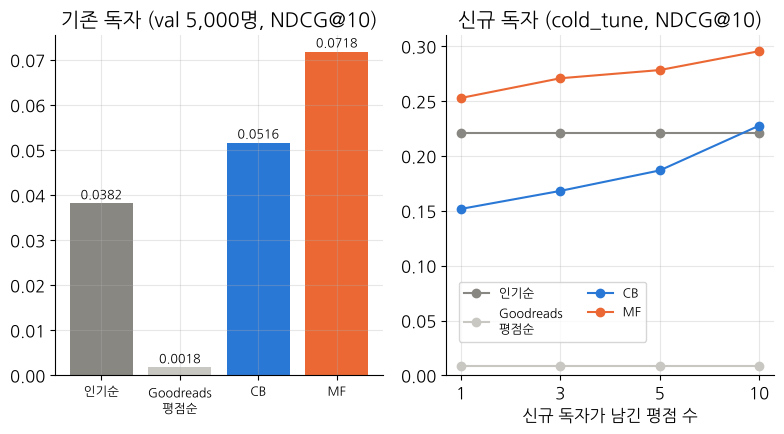

In [5]:
# NOTE: "\n"은 줄바꿈이다. 막대 아래 이름이 옆 이름과 겹치지 않게 두 줄로 쓴다.
LABELS = {"popularity": "인기순", "goodreads_rating": "Goodreads\n평점순", "mf_ranking": "MF", "cb": "CB"}
COLORS = {"popularity": MODEL_COLORS["baseline"], "goodreads_rating": "#c9c7c1", "mf_ranking": MODEL_COLORS["mf"], "cb": MODEL_COLORS["cb"]}
table = scores.pivot(index="goal", columns="model", values="ndcg@10")
fig, (left, right) = plt.subplots(1, 2)
names = list(models)
left.bar([LABELS[name] for name in names], [table.loc["warm_val", name] for name in names], color=[COLORS[name] for name in names])
for x, name in enumerate(names):
    left.annotate(f"{table.loc['warm_val', name]:.4f}", (x, table.loc["warm_val", name]), textcoords="offset points", xytext=(0, 3), ha="center", fontsize=9)
left.set_title("기존 독자 (val 5,000명, NDCG@10)")
# NOTE: tick_params(axis="x", labelsize=9)는 x축 글자 크기를 줄여 이름이 서로 겹치지 않게 한다.
left.tick_params(axis="x", labelsize=9)
sizes = [str(size) for size in COLD_HISTORY_SIZES]
for name in names:
    right.plot(sizes, [table.loc[f"cold_tune_{size}", name] for size in COLD_HISTORY_SIZES], color=COLORS[name], marker="o", label=LABELS[name])
right.set_ylim(0, None)
right.set_xlabel("신규 독자가 남긴 평점 수")
right.set_title("신규 독자 (cold_tune, NDCG@10)")
# NOTE: bbox_to_anchor=(0.02, 0.08)은 범례의 왼쪽 아래 모서리를 그래프 안 (가로 2%, 세로 8%) 위치에 둔다. 아래쪽 선을 가리지 않게 한다.
right.legend(fontsize=9, loc="lower left", bbox_to_anchor=(0.02, 0.08), ncol=2)
save(fig, "C2c_mf_vs_baselines")
plt.show()